**pandas** - работи со табели: читање фајлови, филтрирање, мешање <br>
**AutoTokenizer** - го претвора текстот во броеви и обратно, бидејќи моделите не читаат букви, само броеви<br>
**AutoModelForSeq2SeqLM** - encoder-decoder модел (T5, FLAN-T5, BART). "Auto" значи дека сам ја избира точната класа според името на моделот. <br>
**SentenceTransformer, util** - модели што прават embeddings (вектори од значењето) и функции за споредба меѓу нив.


| Тип модел | Класа | Примери |
|---|---|---|
| Encoder-decoder | `AutoModelForSeq2SeqLM` | T5, FLAN-T5, BART |
| Decoder-only | `AutoModelForCausalLM` | GPT-2, Llama, Mistral |
| Encoder со класификациска глава | `AutoModelForSequenceClassification` | BERT, RoBERTa |


<br>

Табелата одговара на прашањето "која класа ја пишувам во from_pretrained" за мојот модел? <br>

**Encoder** = читач (го чита целиот текст одеднаш, во двете насоки и го разбира, не пишува ништо)<br>
**Decoder** = писател (пишува текст збор по збор, секој нов збор врз основа на претходните)
<br>

Трите типови во табелата се трите начини како се комбинираат овие 2<br>
**1. Encoder-decoder** -> AutoModelForSeq2SeqLM <br>
- Само писател. Како autocomplete на телефонот: го зема почетокот и продолжува.
- Читач + писател (како преведувач: прво ја чита целата реченица, па потоа го пишува одговорот)<br>
  - Влез: текст, Излез: нов, различен текст.
  - Добар за: превод, сумарзизација, класификација преку prompt.
  - Примери: T5, FLAN-T5, BART. <br>

**2. Decoder-only** -> AutoModelForCasualLM<br>
- Само писател, како autocomplete на телефонот: го зема почетокот и го продолжува.
  - Влез: почеток на текст, Излез: истиот текст + продолжение.
  - Добар за: chatbot, генерирање текст. Денешните големи модели од предавањето се од овој тип.
  - Примери: GPT-2, Llama, Mistral. <br>

**3. Encoder + класификациска глава** -> AutoModelForSequenceClassification<br>
- Само читач + оценувач. Го чита текстот и става ознака, не пишува ништо.
- Глава е мал дополнителен слој на врвот на моделот. Наместо текст, тој враќа по еден број за секоја класа, а ние ја зимаме класата со најголем број.
  - Влез: текст, Излез: класа (positive/negative, spam/not spam...).
  - Добар за: класификација кога имаме означени (лабелирани) податоци за тренирање.
  - Примери: BERT, RoBERTa<br>


In [82]:
import pandas as pd
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer
from sentence_transformers import SentenceTransformer, util

**Што прави**: само зачувува име, тоа е адреса на моделот на Hugging Face Hub. <br>
**Зошто ни треба**: кога сакаш да пробаш друг модел, го менуваш само овој ред, се друго останува исто. <br>
small/base/large е големината. Поголем модел е попаметен, но побавен и бара повеќе меморија.  <br>
t5-* наспроти flan-t5-*: FLAN верзијата е тренирана на инструкции, се работи за ист модел, различно научен. <br>
  - Како е трениран T5? <br>
    **Влез**: Thank you <extra_id_0> me to your party <extra_id_1> week.
    **Излез**: <extra_id_0> for inviting <extra_id_1> last <extra_id_2>

      - **T5 ги знае само овие точни формулации**, ако напишеш "Classify the following text", тоа никогаш не го видел, па се враќа на она што најдобро го знае: **ПОПОЛНУВАЊЕ ПРАЗНИНИ**.

  - Што додава FLAN-T5 <br>
    FLAN-T5 почнува од T5, а потоа дополнително fine-tuned на голем број различни задачи (околу 1800). Секоја задача е напишана како инструкција и на многу различни начини.
    - Пример:
    Is the sentiment of this review positive or negative? <br>Review: the food was cold   →  negative <br>
    Review: the food was cold. Did the reviewer like the place?                     →  no

    - Затоа што видел толку многу формулации, научил општо да следи инструкции, а не само фиксни команди.
    

In [83]:
model_name = 't5-large' #t5-small, t5-base, t5-large, google/flan-t5-small

**from_pretrained** го симнува моделот првиот пат (поради тоа има progress bars) и го чува на диск. Следниот пат го чита од таму без да го симнува. <br>
Зошто и двете со исто име? <br>
- Секој модел има свој речник, каде на пример бројот 4501 значи одреден збор. Ако токенизаторот е од еден модел, а моделот од друг, броевите ќе значат погрешни зборови. <br>
**ВАЖНО: tokenizer и model секогаш одат во пар, со исто model_name**.

In [84]:
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

Loading weights:   0%|          | 0/509 [00:00<?, ?it/s]

In [85]:
data = pd.read_csv('yelp.txt', sep='\t')

In [86]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Sentence  2000 non-null   object
 1   Style     2000 non-null   object
dtypes: object(2)
memory usage: 31.4+ KB


**frac=1** ги меша сите 2000 реда бидејќи во фајлот се подредени прво сите негативни, па сите позитивни. <br>
**ignore_index=True** ги пренумерира редовите од 0 до 1999

In [87]:
data = data.sample(frac=1, ignore_index=True)

In [88]:
data.sample(5)

,Sentence,Style
1656,the woman didn't even apologize.,negative
1787,she would have apologised but she was in a hurry,positive
1884,the tzatziki sauce had the right amount of dill,positive
605,so i asked for the card to be refunded.,negative
4,they are usually very warm,positive


Токенизаторот и моделите од Hugging Face примаат стринг или листа од стрингови. Поради тоа што Sentence и Style се Series, тие мора прво да се претворат во листи.

In [89]:
sentences = data['Sentence'].values.tolist()
labels = data['Style'].values.tolist()

Пробуваме прво дали моделот работи на една реченица пред да го пуштаме на целиот dataset.

In [90]:
sample_sentence = sentences[5]
sample_label = labels[5]
print(sample_sentence)
print(sample_label)

the food was so-so and very over priced for what you get.
negative


Го пишуваме promot-от кој сакаме да му го дадеме на моделот

In [91]:
prompt = f'Classify the following text into either \'POSITIVE\' or \'NEGATIVE\': {sample_sentence}'
prompt

"Classify the following text into either 'POSITIVE' or 'NEGATIVE': the food was so-so and very over priced for what you get."

Моделот не може да чита букви, работи само со броеви. <br>
Токенизаторот го сече prompt-от на парчиња (токени, обично делови од зборови) и секое парче го заменува со негивиот број од речникот на t5-large. <br>
Враќа две работи:
  1. **input_ids**: броевите за секое парче, 41 вкупно. Последниот 1 е знакот за крај </s> кој токенизаторот сам го додава.
  2. **attention_mask**: по една 1 за секој токен. Му кажува на моделот кои токени се вистински и треба да ги гледа.

**return_tensors='pt'**: врати ги броевите како PyTorch тензори, а не како обични листи. Моделот е PyTorch модел и прима само тензори.<br>
Ова е prompt-от претворен во облик што моделот може да го прочита.

In [92]:
tokens = tokenizer(prompt, return_tensors='pt')

**tokens.input_ids** се 41 број, prompt-от претворен во токени (од cell 7). tokens има два дела, input_ids и attention_mask, тука се зема само input_ids. <br>
**generate** - функција со која моделот пишува одговор. Не го пишува одеднаш, туку токен по токен, како кога пишуваш порака збор по збор. <br>
**Чекор по чекор**: <br>
1. Енкодерот ги чита сите 41 токени од prompt-от одеднаш и ,,разбира" што пишува.
2. Декодерот почнува со токенот 0, знакот значи ,,почни да пишуваш".
3. Гледа во prompt-от во она што досега го напишал и го бира најверојатниот следен токен.
4. Го додава тој токен и пак го повторува чекор 3.
5. Застанува кога ќе го напише токенот за крај или кога ќе стигне до максималната должина.

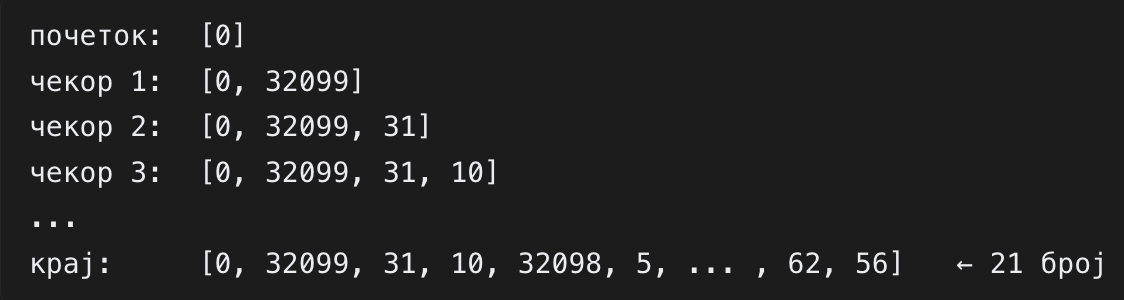

Што добиваме?<br>
- output_ids се броеви, не текст: <br>
tensor([[0, 32099, 31, 10, 32098, 5, 32097, ...]]) <br>

Пак е [[...]]: еден одговор, за еден prompt.<br>
0 на почетокот е почетниот знак од чекор 2.<br>
32099, 32098, 32097 се специјални токени, <extra_id_0>, <extra_id_1>,... со нив T5 означува празнини, бидејќи е трениран за тоа.<br>
Ова е моментот кога моделот го создава одговорот. Бидејќи моделот работи само со броеви, и одговорот е во броеви. Затоа следно користиме декодер за да го претвориме назад во текст

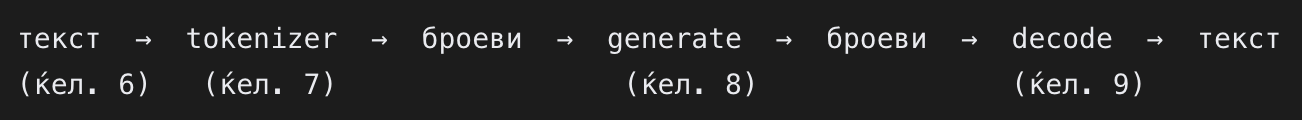

In [93]:
output_ids = model.generate(tokens.input_ids)
output_ids

/usr/local/lib/python3.13/dist-packages/transformers/generation/utils.py:1969: UserWarning: Using the model-agnostic default `max_length` (=21) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


tensor([[    0, 32099,     3,    31, 16034,  3177,  8087,    31,    42,     3,
            31,  4171,  6302,   382,  8087,    31,    10,     8,   542,    47,
            78]])

output_ids[0] - output_ids има двојни загради [[...]], односно листа од одговори. Имаме еден prompt, па има еден одговор. [0] го вади тој еден одговор. <br>
Ова се прави бидејќи decode преведува еден одговор, а не листа од одговори.<br>
tokenizer.decode(...) - секој број го бара во речникот и го заменува со неговото парче текст, па сите парчиња ги спојува во една реченица <br>
skip_special_tokens=True ги тга специјалните токени, односно:
1. 0 = <pad> почетен знак
2. 32099, 32098, 32097 = <extra_id_N> - ознаки за празнини
3. 1 = </s> знак за крај

In [94]:
tokenizer.decode(output_ids[0], skip_special_tokens=True)

"'POSITIVE' or 'NEGATIVE': the food was so"

---------------------------------------
---------------------------------------
---------------------------------------
---------------------------------------
---------------------------------------
---------------------------------------
---------------------------------------

**Чекор 1: few-shot со слични примери**



In [96]:
embedding_model = SentenceTransformer('all-distilroberta-v1')

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.1k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/653 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  328MB            

... (4 outputs left out)

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

**embedding** - листа од броеви што го опишува значењето на текстот. <br>
- Компјутерот не може директно да каже дали две реченици значат слично. Но, ако за секоја реченица ја претвориме во броеви, тогаш можеме да пресметаме колку блиску се тие броеви. <br>
- Реченици со слично значење се блиску на мапата, а различните се далеку. <br>
Вистинските embeddings немаат 2, туку 768 броеви. Тоа е мапа со 768 димензии.
<br>

**sentences[:20]** - првите 20 реченици од листата, од позиција 0 до 19. <br>
**.encode(...)**: секоја од 20-те реченици ја претвора во embedding од 768 броеви.<br>
**batch_size=64**: колку реченици се обработуваат одеднап. Има само 20, па сите одат во еден batch. <br>
**embeddings**: резултатот е табела од броеви, 20 реда х 768 колони. Секој ред е една реченица. <br>

- Ова ни треба бидејќи ова ни е корпусот, групата реченици во која подоца се бараат реченици слични на нашата.

In [101]:
embeddings = embedding_model.encode(sentences[:20], batch_size=64)
embeddings.shape

(20, 768)

In [102]:
query_emb = embedding_model.encode([sample_sentence], batch_size=64)
query_emb.shape

(1, 768)

In [103]:
hits = util.semantic_search(query_emb, embeddings, top_k=10)[0]

examples = ''
for hit in hits:
  i = hit['corpus_id']
  if sentences[i] == sample_sentence:
    continue
  examples += f'Input: {sentences[i]} Output: {labels[i].upper()}\n'

prompt_similar = f'Examples:\n{examples}Classify the following text into either \'POSITIVE\' or \'NEGATIVE\': {sample_sentence} Output: '
print(prompt_similar)

Examples:
Input: had a bad time and the food at their restaurant was awful! Output: NEGATIVE
Input: the food here is gross Output: NEGATIVE
Input: awful quality, awful service. Output: NEGATIVE
Input: worst take out or eat in sushi! Output: NEGATIVE
Input: this is a pretty darn bad pizza Output: NEGATIVE
Input: you can not pay me to not ever shop here! Output: POSITIVE
Input: the environment was cozy, the servers were friendly and on top of things. Output: POSITIVE
Input: had one mediocre meal and said, ``we'll try again''. Output: NEGATIVE
Input: first, the bartender was awesome. Output: POSITIVE
Classify the following text into either 'POSITIVE' or 'NEGATIVE': the food was so-so and very over priced for what you get. Output: 


In [104]:
tokens = tokenizer(prompt_similar, return_tensors='pt')
output_ids = model.generate(tokens.input_ids)
tokenizer.decode(output_ids[0], skip_special_tokens=True)

/usr/local/lib/python3.13/dist-packages/transformers/generation/utils.py:1969: UserWarning: Using the model-agnostic default `max_length` (=21) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


'NEGATIVE Input: the food was awful! Output: NEGATIVE'

**Чекор 2: одвојување на примерите од речениците за тест**
<br>
Ако не се направи одвојување, моделот би го добил точниот одговор во prompt-от, па затоа речениците од кои се вадат примери треба да се одделени од речениците што се тестираат.
<br>
 Идеја: 2000те реченици се делат на два дела:
 1. train: од тука се вадат примерите за prompt-от
 2. test: тие се класифицираат и никогаш не се појавуваат како примери

In [112]:
train_sentences = sentences[:1800]
train_labels = labels[:1800]

test_sentences = sentences[1800:]
test_labels = labels[1800:]

len(train_sentences), len(test_sentences)

(1800, 200)

In [113]:
train_emb = embedding_model.encode(train_sentences, batch_size=64)
train_emb.shape

(1800, 768)

In [114]:
test_sentence = test_sentences[0]
query_emb = embedding_model.encode([test_sentence], batch_size=64)

hits = util.semantic_search(query_emb, train_emb, top_k=5)[0]
hits

[{'corpus_id': 1753, 'score': 0.723514199256897},
 {'corpus_id': 1162, 'score': 0.5053383111953735},
 {'corpus_id': 97, 'score': 0.4265002906322479},
 {'corpus_id': 1164, 'score': 0.41640573740005493},
 {'corpus_id': 1649, 'score': 0.4047797918319702}]

In [115]:
examples = ''
for hit in hits:
    i = hit['corpus_id']
    examples += f'Input: {train_sentences[i]} Output: {train_labels[i].upper()}\n'

prompt_similar = f'Examples:\n{examples}Classify the following text into either \'POSITIVE\' or \'NEGATIVE\': {test_sentence} Output: '
print(prompt_similar)

Examples:
Input: the mechanics are very professional as usual. Output: POSITIVE
Input: the equipment is so old and looks dirty. Output: NEGATIVE
Input: The equipment is very new and looks good. Output: POSITIVE
Input: unfortunately, the tour guides are not experts. Output: NEGATIVE
Input: the tech did not know what to do Output: NEGATIVE
Classify the following text into either 'POSITIVE' or 'NEGATIVE': the mechanics are very amateur as usual. Output: 


In [121]:
tokens = tokenizer(prompt_similar, return_tensors='pt')
output_ids = model.generate(tokens.input_ids)
print('Model:', tokenizer.decode(output_ids[0], skip_special_tokens=True))
print('Correct:', test_labels[0])

/usr/local/lib/python3.13/dist-packages/transformers/generation/utils.py:1969: UserWarning: Using the model-agnostic default `max_length` (=21) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


Model: POSITIVE POSITIVE The equipment is so old and looks dirty. Out
Correct: negative


In [122]:
import re

In [123]:
def clean_answer(text):
  found = re.findall(r'positive|negative', text.lower())
  return found[0] if found else 'unknown'

In [124]:
def classify(sentence):
    query_emb = embedding_model.encode([sentence])
    hits = util.semantic_search(query_emb, train_emb, top_k=5)[0]

    examples = ''
    for hit in hits:
        i = hit['corpus_id']
        examples += f'Input: {train_sentences[i]} Output: {train_labels[i].upper()}\n'

    prompt = f'Examples:\n{examples}Classify the following text into either \'POSITIVE\' or \'NEGATIVE\': {sentence} Output: '

    tokens = tokenizer(prompt, return_tensors='pt')
    output_ids = model.generate(tokens.input_ids, max_new_tokens=5)
    answer = tokenizer.decode(output_ids[0], skip_special_tokens=True)
    return clean_answer(answer)

In [125]:
N = 100
correct = 0
predictions = []

for j in range(N):
    pred = classify(test_sentences[j])
    predictions.append(pred)
    if pred == test_labels[j]:
        correct += 1

print('Accuracy:', correct / N)
print('No answer (unknown):', predictions.count('unknown'))

Accuracy: 0.25
No answer (unknown): 19


In [126]:
print('positive:', predictions.count('positive'))
print('negative:', predictions.count('negative'))

positive: 53
negative: 28


In [127]:
def zero_shot_prompt(sentence):
    return f'Classify the following text into either \'POSITIVE\' or \'NEGATIVE\': {sentence}'


def fixed_few_shot_prompt(sentence):
    examples = 'Input: so basically tasted watered down. Output: NEGATIVE.\nInput: ron is still the greatest. Output: POSITIVE'
    return f'Examples:\n{examples}\nClassify the following text into either \'POSITIVE\' or \'NEGATIVE\': {sentence}. Output: '


def similar_few_shot_prompt(sentence):
    query_emb = embedding_model.encode([sentence])
    hits = util.semantic_search(query_emb, train_emb, top_k=5)[0]
    examples = ''
    for hit in hits:
        i = hit['corpus_id']
        examples += f'Input: {train_sentences[i]} Output: {train_labels[i].upper()}\n'
    return f'Examples:\n{examples}Classify the following text into either \'POSITIVE\' or \'NEGATIVE\': {sentence} Output: '

In [128]:
def ask_model(prompt):
    tokens = tokenizer(prompt, return_tensors='pt')
    output_ids = model.generate(tokens.input_ids, max_new_tokens=5)
    return tokenizer.decode(output_ids[0], skip_special_tokens=True)


def evaluate(build_prompt, N=100):
    correct = 0
    predictions = []
    for j in range(N):
        prompt = build_prompt(test_sentences[j])
        pred = clean_answer(ask_model(prompt))
        predictions.append(pred)
        if pred == test_labels[j]:
            correct += 1
    return correct / N, predictions.count('unknown')

In [129]:
zs_acc, zs_unk = evaluate(zero_shot_prompt)
fs_acc, fs_unk = evaluate(fixed_few_shot_prompt)
ss_acc, ss_unk = evaluate(similar_few_shot_prompt)

pd.DataFrame({
    'prompt': ['zero-shot', 'fixed few-shot', 'similar few-shot'],
    'accuracy': [zs_acc, fs_acc, ss_acc],
    'unknown': [zs_unk, fs_unk, ss_unk],
})

,prompt,accuracy,unknown
0,zero-shot,0.00,99
1,fixed few-shot,0.26,44
2,similar few-shot,0.25,19


In [131]:
all_results = [
    {'model': 't5-large', 'zero-shot': zs_acc, 'fixed few-shot': fs_acc, 'similar few-shot': ss_acc},
]

for name in ['google/flan-t5-base', 'google/flan-t5-large']:
    tokenizer = AutoTokenizer.from_pretrained(name)
    model = AutoModelForSeq2SeqLM.from_pretrained(name)

    zs, _ = evaluate(zero_shot_prompt)
    fs, _ = evaluate(fixed_few_shot_prompt)
    ss, _ = evaluate(similar_few_shot_prompt)

    all_results.append({'model': name, 'zero-shot': zs, 'fixed few-shot': fs, 'similar few-shot': ss})

pd.DataFrame(all_results)

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Loading weights:   0%|          | 0/558 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


,model,zero-shot,fixed few-shot,similar few-shot
0,t5-large,0.00,0.26,0.25
1,google/flan-t5-base,0.92,0.91,0.91
2,google/flan-t5-large,0.86,0.94,0.87
